# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


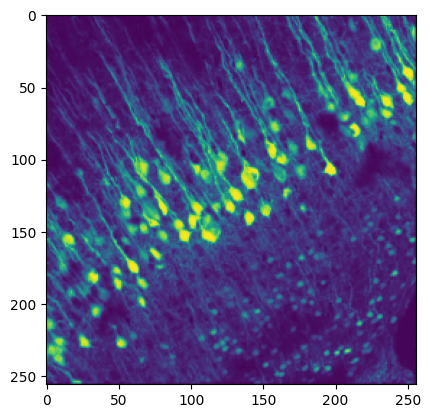

In [7]:
cell_img = plt.imread('data/cells.png')
cell_img = resize(cell_img, (256, 256))
plt.figure()
plt.imshow(cell_img)

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [9]:
cell_ft = np.fft.fft2(cell_img)

**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [11]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

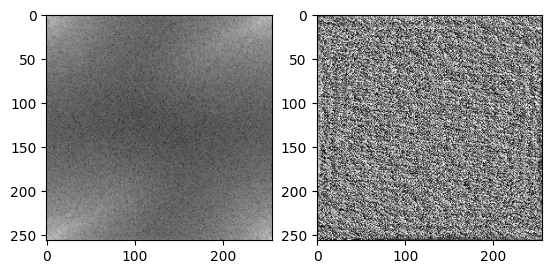

In [12]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


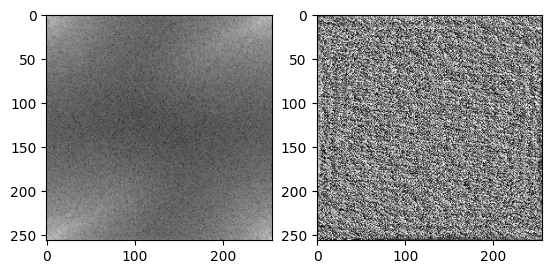

In [15]:
np.fft.fftshift(cell_ft)
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


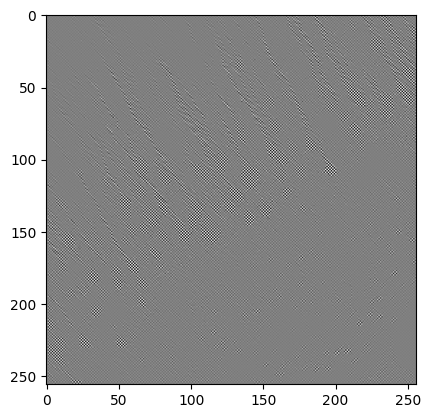

In [20]:
cell_ft_unshifted = np.fft.ifftshift(cell_ft)
cell_invfft = np.fft.ifft2(cell_ft_unshifted)
plt.figure()
plt.imshow(cell_invfft.real, cmap='gray')

---


**[Task 2 (a).]()** Load the brain MR image.


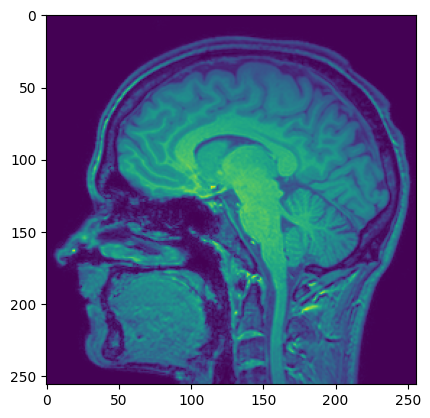

In [25]:
brain = plt.imread('data/brain_mri.png')
brain = resize(brain, (256, 256))
plt.figure()
plt.imshow(brain)

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


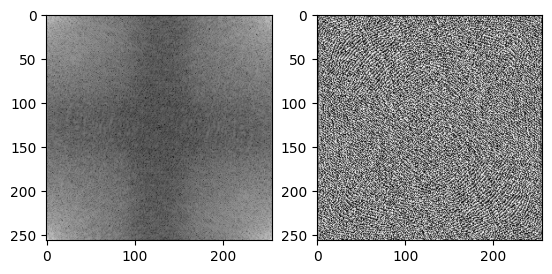

In [30]:
brain_ft = np.fft.fft2(brain)
np.fft.fftshift(brain_ft)
amplitude = np.abs(brain_ft)
phase = np.angle(brain_ft)
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

In [31]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


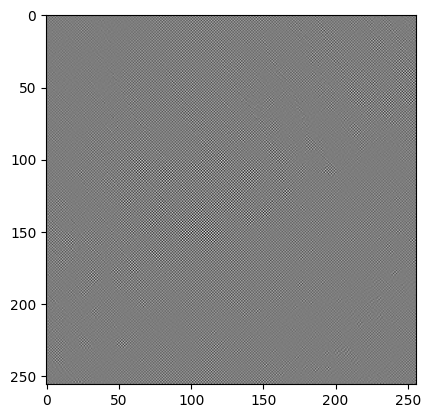

In [34]:
amp_brain = np.abs(brain_ft)
phase_cell = np.angle(cell_ft)
merged_1 = to_complex_array(amp_brain, phase_cell)
restored_1 = np.fft.ifft2(np.fft.ifftshift(merged_1))
plt.figure()
plt.imshow(restored_1.real, cmap='gray')
plt.show()

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


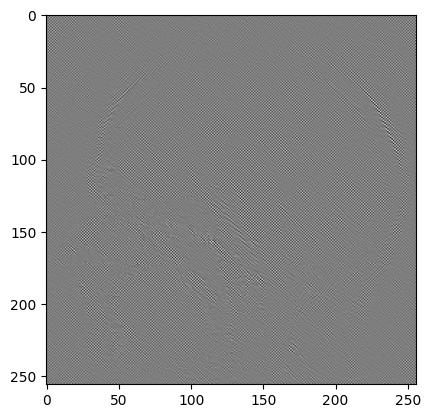

In [36]:
amp_cell = np.abs(cell_ft)
phase_brain = np.angle(brain_ft)
merged_2 = to_complex_array(amp_cell, phase_brain)
restored_2 = np.fft.ifft2(np.fft.ifftshift(merged_2))
plt.figure()
plt.imshow(restored_2.real, cmap='gray')
plt.show()

---


**[Task 3 (a).]()** Create a lowpass filter mask.


In [40]:
filter_window_size = 50
lowpass_mask = np.zeros((rows, cols))
rows, cols = brain.shape
center_row, center_col = rows // 2, cols // 2
r1, r2 = center_row - filter_window_size // 2, center_row + filter_window_size // 2
c1, c2 = center_col - filter_window_size // 2, center_col + filter_window_size // 2
lowpass_mask[r1:r2, c1:c2] = 1

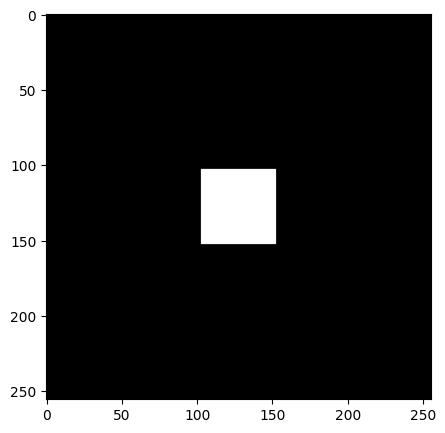

In [ ]:
plt.figure(figsize=(5, 5))
plt.imshow(lowpass_mask, cmap='gray')


**[Task 3 (b).]()** Create a highpass filter maks.


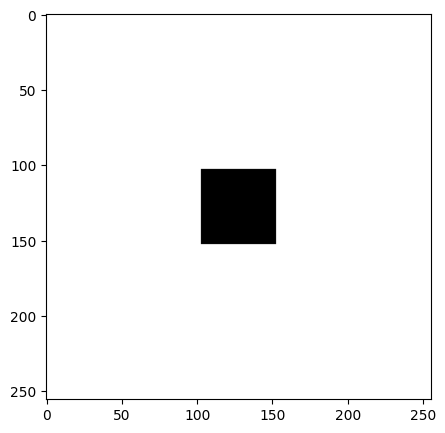

In [43]:
highpass_mask = 1 - lowpass_mask
plt.figure(figsize=(5, 5))
plt.imshow(highpass_mask, cmap='gray')

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


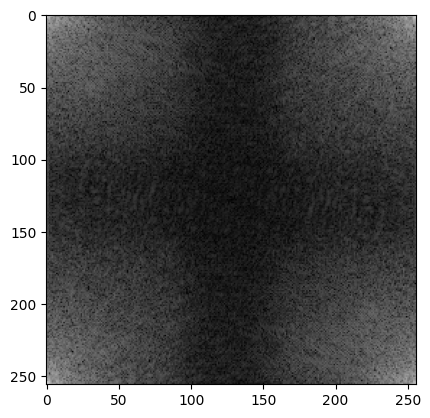

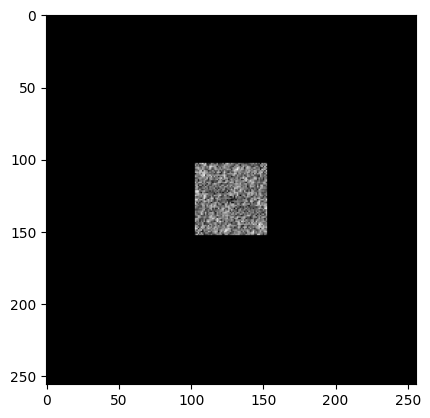

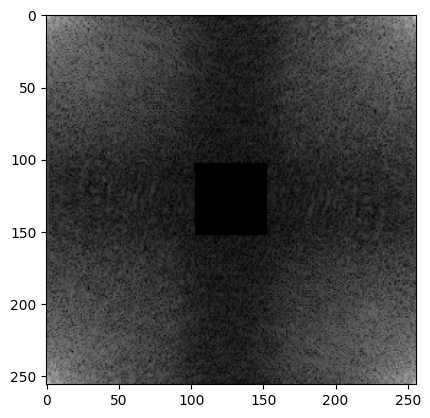

In [49]:
brain_amp = np.abs(brain_ft)
brain_amp_lp = brain_amp * lowpass_mask
brain_amp_hp = brain_amp * highpass_mask
plt.figure()
plt.imshow(np.log(1 + brain_amp), cmap='gray')
plt.show()
plt.figure()
plt.imshow(np.log(1 + brain_amp_lp), cmap='gray')
plt.show()
plt.figure()
plt.imshow(np.log(1 + brain_amp_hp), cmap='gray')
plt.show()

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


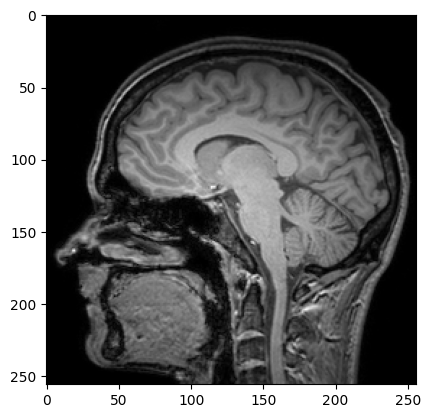

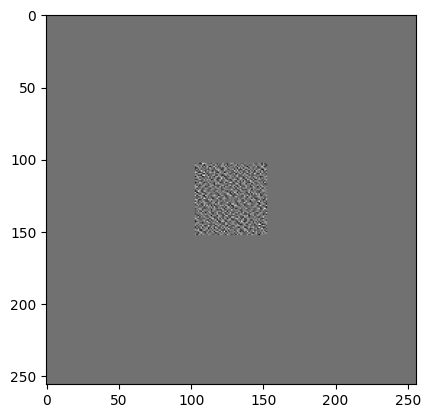

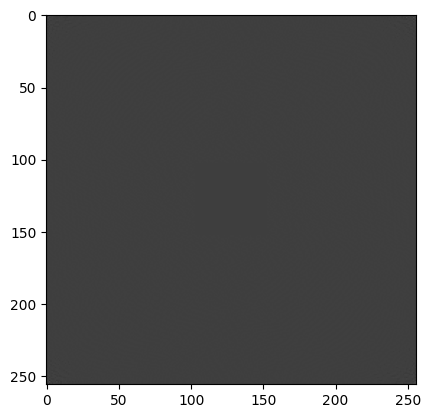

In [50]:
brain_phase = np.angle(brain_ft)
merged_lp = brain_amp_lp * np.exp(1j * brain_phase)
merged_hp = brain_amp_hp * np.exp(1j * brain_phase)
restored_lp = np.fft.ifft2(np.fft.ifftshift(merged_lp))
restored_hp = np.fft.ifft2(np.fft.ifftshift(merged_hp))
plt.figure()
plt.imshow(brain, cmap='gray')
plt.show()
plt.figure()
plt.imshow(merged_lp.real, cmap='gray')
plt.show()
plt.figure()
plt.imshow(merged_hp.real, cmap='gray')
plt.show()

---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [60]:
def my_dft(img):
    M, N = img.shape
    dft = np.zeros((M, N), dtype=complex)
    for u in range(M):
        for v in range(N):
            x = np.arange(M)[:, None]
            y = np.arange(N)[None, :]
            term = img * np.exp(-2j * np.pi * ((u * x / M) + (v * y / N)))
            dft[u, v] = np.sum(term) / (M * N)
    return dft

**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [68]:
def my_idft(img):
    M, N = img.shape
    idft = np.zeros((M, N), dtype=complex)
    for x in range(M):
        for y in range(N):
            u = np.arange(M)[:, None]
            v = np.arange(N)[None, :]
            term = img * np.exp(2j * np.pi * ((u * x / M) + (v * y / N)))
            idft[x, y] = np.sum(term)     
    return idft

Due to high computational costs, we need to resize the image.


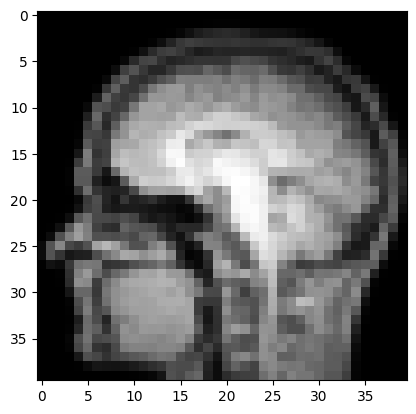

In [62]:
test_img = resize(brain, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


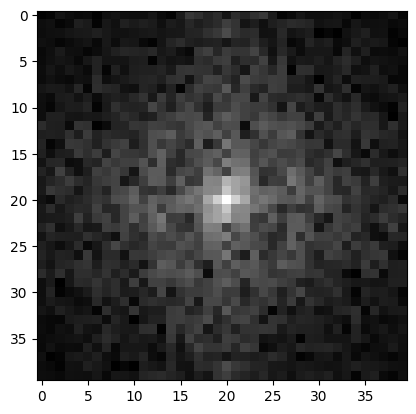

/tmp/ipykernel_1740/2174088142.py:11: RuntimeWarning: invalid value encountered in log
  plt.imshow(np.log(1 + own_phase), cmap='gray')


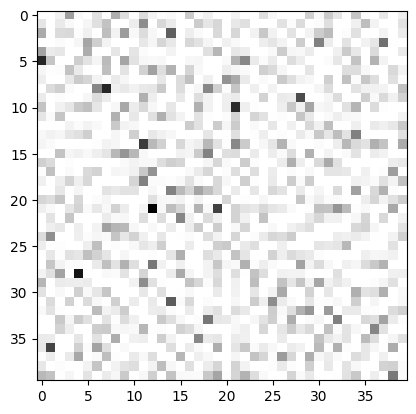

In [66]:

own_dft = my_dft(test_img)
own_dft_shifted = np.fft.fftshift(own_dft)
own_amp = np.abs(own_dft_shifted)
own_phase = np.angle(own_dft_shifted)

plt.figure()
plt.imshow(np.log(1 + own_amp), cmap='gray')
plt.show()

plt.figure()
plt.imshow(np.log(1 + own_phase), cmap='gray')
plt.show()

**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


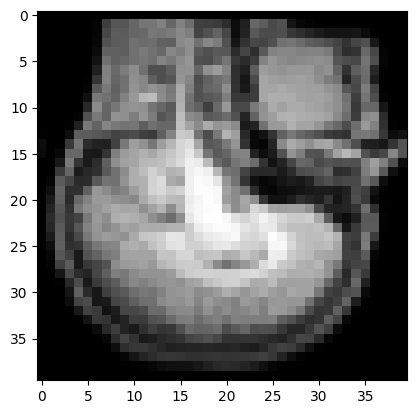

In [69]:
own_restored = my_idft(own_dft)
plt.figure()
plt.imshow(own_restored.real, cmap='gray')
plt.show()

**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


In [70]:
np_fft_result = np.fft.fft2(test_img, norm='forward')
are_close = np.allclose(own_dft, np_fft_result)
print(are_close)

False


**[Task 4 (f).]()** Round the arrays and compare them again.


In [ ]:
mean_diff = np.mean(np.abs(own_dft - np_fft_result))
decimals = 5
rounded_own = np.round(own_dft, decimals)
rounded_np = np.round(np_fft_result, decimals)
exact_match = (rounded_own == rounded_np).all()
print(f"Exakter Match bei {decimals} Dezimalstellen: {exact_match}")

**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
